<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h1>Homework Task 3: Feature Selection</h1>

<p>Our goal is to find a smaller and interpretable  feature set while keeping predictive performance.

We compare three approaches:

* Filter methods: mutual information and analysis of redundancy.
* Wrapper methods: recursive feature elimination
* Embedded methods: L1-regularized logistic regression

We compare predictive performance, feature count and selection stability. </p>

<h2>Contents</h2>

<ol>
  <li><a href="#setup">Setup and import</a></li>
  <li><a href="#candidates">Candidate features and preprocessing</a></li>
  <li><a href="#validation">Validation strategy and reference performance</a></li>
  <li><a href="#filter">Filter methods</a></li>
  <li><a href="#wrapper">Wrapper methods</a></li>
  <li><a href="#embedded">Embedded methods</a></li>
  <li><a href="#comparison">Comparison and final feature set</a></li>

</ol>

</div>

<a id="setup"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>1. Setup and import</h2>
<p> Laod the training data and remove the rows as in Task 2</p>
</div>

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import RFE

# Import preprocessing.py from "Final"-Folder
cwd = Path.cwd()

if (cwd / "Final" / "preprocessing.py").is_file():
    FINAL_DIR = cwd / "Final"
elif cwd.name == "Final" and (cwd / "preprocessing.py").is_file():
    FINAL_DIR = cwd
else:
    raise FileNotFoundError(
        "Run this notebook from the repository root or its Final folder."
    )

sys.path.insert(0, str(FINAL_DIR))
from preprocessing import preprocessor

DATA_DIR = FINAL_DIR.parent / "data"

RANDOMSTATE = 42
TARGET = "repeat_purchase_90d"
THRESHOLD = 0.5

def binary_f1(y_true, probabilities):
    predictions = (probabilities >= THRESHOLD).astype(int)
    return f1_score(y_true, predictions, pos_label=1, zero_division=0)

sns.set_theme(style="whitegrid")

In [23]:
trainraw = pd.read_csv(DATA_DIR / "train.csv")

# Apply the same row exclusion as Task 2.
featurecols = [
    col for col in trainraw.columns
    if col not in ["ID", "customer_id", TARGET]
]

empty = trainraw[featurecols].isna().all(axis=1)
train = trainraw.loc[~empty].reset_index(drop=True)

X = train.drop(columns=TARGET)
y = train[TARGET]
groups = train["customer_id"]

assert y.notna().all(), "Missing target values."
assert set(y.unique()) == {0, 1}, "Expected target values 0 and 1."
assert groups.notna().all(), "Missing customer IDs."

display(
    pd.Series({
        "Original rows": len(trainraw),
        "Empty rows removed": int(empty.sum()),
        "Remaining rows": len(train),
        "Customers": groups.nunique(),
        "Repeat rate": round(y.mean(), 3),
    }, name="Value").to_frame()
)

,Value
Original rows,6534.00
Empty rows removed,65.00
Remaining rows,6469.00
Customers,607.00
Repeat rate,0.56


<a id="candidates"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>2. Candidate features and preprocessing</h2>
<p> Reuse candidate features and preprocessing from Task 2. </p>
</div>

In [24]:
NUMERIC = [
    "Total Liquido", "Total Imp_", "Total Portes",
    "Total Desc_ Global", "Total Desc_ Linha", "Custo",
    "N_ Detalhes", "invoice_count_current_purchase",
    "days_since_previous_purchase", "customer_tenure_days",
    "prior_purchase_count", "prior_total_spend",
    "prior_mean_purchase_value", "prior_std_purchase_value",
    "prior_min_purchase_value", "prior_max_purchase_value",
    "prior_mean_gap_days", "prior_std_gap_days",
    "purchase_count_30d", "spend_30d",
    "purchase_count_90d", "spend_90d",
    "purchase_count_180d", "spend_180d",
    "purchase_count_365d", "spend_365d",
]

CATEGORICAL = [
    "payment_type", "salesperson", "commercial_zone",
    "transport_method", "month",
]

flags = [
    "is_first_purchase", "has_gap_history",
    "typical_gap_le_90", "zero_cost", "has_shipping",
]

# Keep NUMERIC unchanged, matching Task 2.
numeric_features = NUMERIC + ["purchases_per_year", "discount_rate"]

pipeline = preprocessor(numeric_features, flags, CATEGORICAL)

display(
    pd.Series({
        "Numeric features": len(numeric_features),
        "Binary flags": len(flags),
        "Categorical variables": len(CATEGORICAL),
        "Total before one-hot encoding":
            len(numeric_features) + len(flags) + len(CATEGORICAL),
    }, name="Count").to_frame()
)

,Count
Numeric features,28
Binary flags,5
Categorical variables,5
Total before one-hot encoding,38


<a id="validation"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>3. Validation strategy and reference performance</h2>
<p> Evaluate logistic regression with all candidate features using five customer-based folds and F1-Score. 
(Repeat of Task 2 7.2 to make the Notebook running independent and stores scores for later comparsion)</p>
</div>

In [25]:
splits = list(GroupKFold(n_splits=5).split(X, y, groups))

reference_model = Pipeline([
    ("preprocessing", pipeline),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOMSTATE,
    )),
])

reference_rows = []

for fold, (trainidx, validx) in enumerate(splits, start=1):
    # Verify that customers do not overlap.
    train_customers = set(groups.iloc[trainidx])
    val_customers = set(groups.iloc[validx])
    assert train_customers.isdisjoint(val_customers)

    fitted = clone(reference_model)
    fitted.fit(X.iloc[trainidx], y.iloc[trainidx])

    probabilities = fitted.predict_proba(X.iloc[validx])[:, 1]

    feature_names = (
        fitted.named_steps["preprocessing"]
        .named_steps["columns"]
        .get_feature_names_out()
    )

    reference_rows.append({
        "Fold": fold,
        "Training rows": len(trainidx),
        "Validation rows": len(validx),
        "Encoded features": len(feature_names),
        "F1": binary_f1(y.iloc[validx], probabilities),
    })

reference_results = pd.DataFrame(reference_rows).set_index("Fold")

display(reference_results.round(4))

print(
    f"Mean F1: {reference_results['F1'].mean():.4f}\n"
    f"Fold standard deviation: {reference_results['F1'].std():.4f}"
)

,Training rows,Validation rows,Encoded features,F1
Fold,,,,
1,5175,1294,90,0.7643
2,5175,1294,92,0.7607
3,5175,1294,91,0.7292
4,5175,1294,92,0.7136
5,5176,1293,88,0.7558


Mean F1: 0.7447
Fold standard deviation: 0.0222


<a id="filter"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>4. Filter methods</h2>
<p>Ranking features by their mutual information with the target by using the first folds training data. </p>
</div>

In [26]:
# Fit preprocessing only on the first fold's training rows.
trainidx, validx = splits[0]

filter_preprocessor = clone(pipeline)
X_filter = filter_preprocessor.fit_transform(X.iloc[trainidx])
y_filter = y.iloc[trainidx]

feature_names = (
    filter_preprocessor.named_steps["columns"].get_feature_names_out()
)

# Binary flags, one-hot columns and counts are discrete variables.
count_features = {
    "N_ Detalhes",
    "invoice_count_current_purchase",
    "prior_purchase_count",
    "purchase_count_30d",
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d",
}

discrete_mask = np.array([
    name.startswith(("flags__", "cat__"))
    or name.split("__", 1)[-1] in count_features
    for name in feature_names
])

# Convert discrete features to integer codes, while keeping continuous features unchanged. Mutual information requires that.
X_mi = X_filter.copy()

for col_idx in np.flatnonzero(discrete_mask):
    X_mi[:, col_idx] = np.unique(
        X_filter[:, col_idx], return_inverse=True
    )[1]

mi_scores = mutual_info_classif(
    X_mi,
    y_filter,
    discrete_features=discrete_mask,
    random_state=RANDOMSTATE,
)

mi_results = (
    pd.DataFrame({
        "Feature": feature_names,
        "Mutual information": mi_scores,
    })
    .sort_values("Mutual information", ascending=False)
    .reset_index(drop=True)
)

display(mi_results.head(20).round(4))

,Feature,Mutual information
0,log__prior_max_purchase_value,0.1504
1,log__prior_min_purchase_value,0.1358
2,log__purchase_count_365d,0.1141
3,log__purchases_per_year,0.1071
4,log__prior_mean_gap_days,0.1039
5,log__purchase_count_180d,0.0935
6,log__spend_180d,0.0846
7,log__purchase_count_90d,0.0832
8,log__spend_365d,0.0802
9,log__prior_purchase_count,0.0762


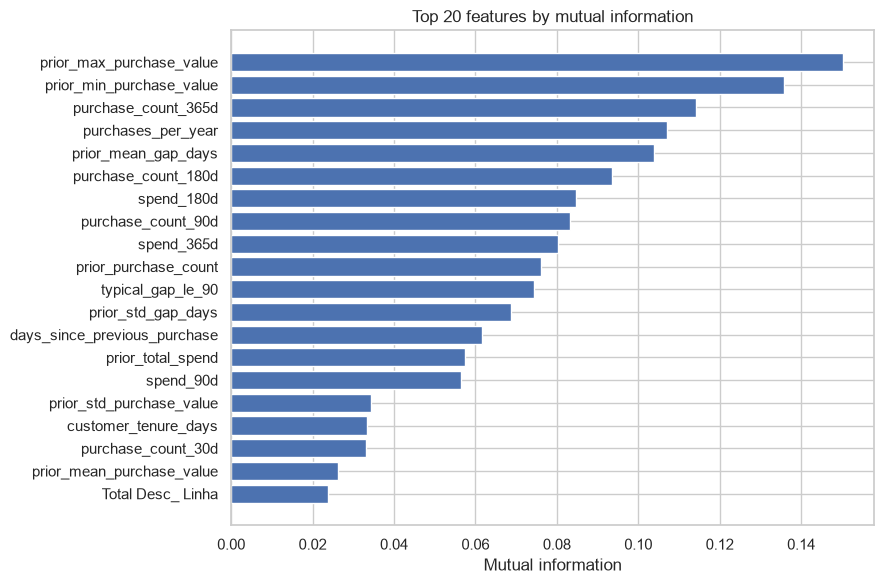

In [27]:
top_mi = mi_results.head(20).sort_values("Mutual information")

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_mi["Feature"].str.replace(r"^[^_]+__", "", regex=True),
    top_mi["Mutual information"],
)

ax.set(
    title="Top 20 features by mutual information",
    xlabel="Mutual information",
    ylabel="",
)

plt.tight_layout()
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.1 Redundancy between numeric features</h3>
<p>Identify strongly correlated numeric features.</p>
</div>

In [28]:
# Reuse the first folds transformed training data.
numeric_mask = np.array([
    name.startswith(("log__", "share__"))
    for name in feature_names
])

X_numeric = pd.DataFrame(
    X_filter[:, numeric_mask],
    columns=[
        name.split("__", 1)[-1]
        for name in feature_names[numeric_mask]
    ],
)

correlation = X_numeric.corr(method="spearman")

# Keep each pair once and exclude correlations with itself.
upper_triangle = np.triu(
    np.ones(correlation.shape, dtype=bool), k=1
)

correlation_pairs = (
    correlation.where(upper_triangle)
    .stack()
    .rename("Spearman correlation")
    .rename_axis(["Feature 1", "Feature 2"])
    .reset_index()
)

correlation_pairs["Absolute correlation"] = (
    correlation_pairs["Spearman correlation"].abs()
)

strong_pairs = (
    correlation_pairs
    .loc[correlation_pairs["Absolute correlation"] >= 0.90]
    .sort_values("Absolute correlation", ascending=False)
    .reset_index(drop=True)
)

display(strong_pairs.round(3))
print("Pairs with absolute correlation ≥ 0.90:", len(strong_pairs))

,Feature 1,Feature 2,Spearman correlation,Absolute correlation
0,purchase_count_30d,spend_30d,0.972,0.972
1,prior_std_purchase_value,prior_max_purchase_value,0.930,0.930
2,prior_total_spend,prior_max_purchase_value,0.914,0.914
3,purchase_count_90d,spend_90d,0.910,0.910
4,prior_purchase_count,prior_total_spend,0.907,0.907


Pairs with absolute correlation ≥ 0.90: 5


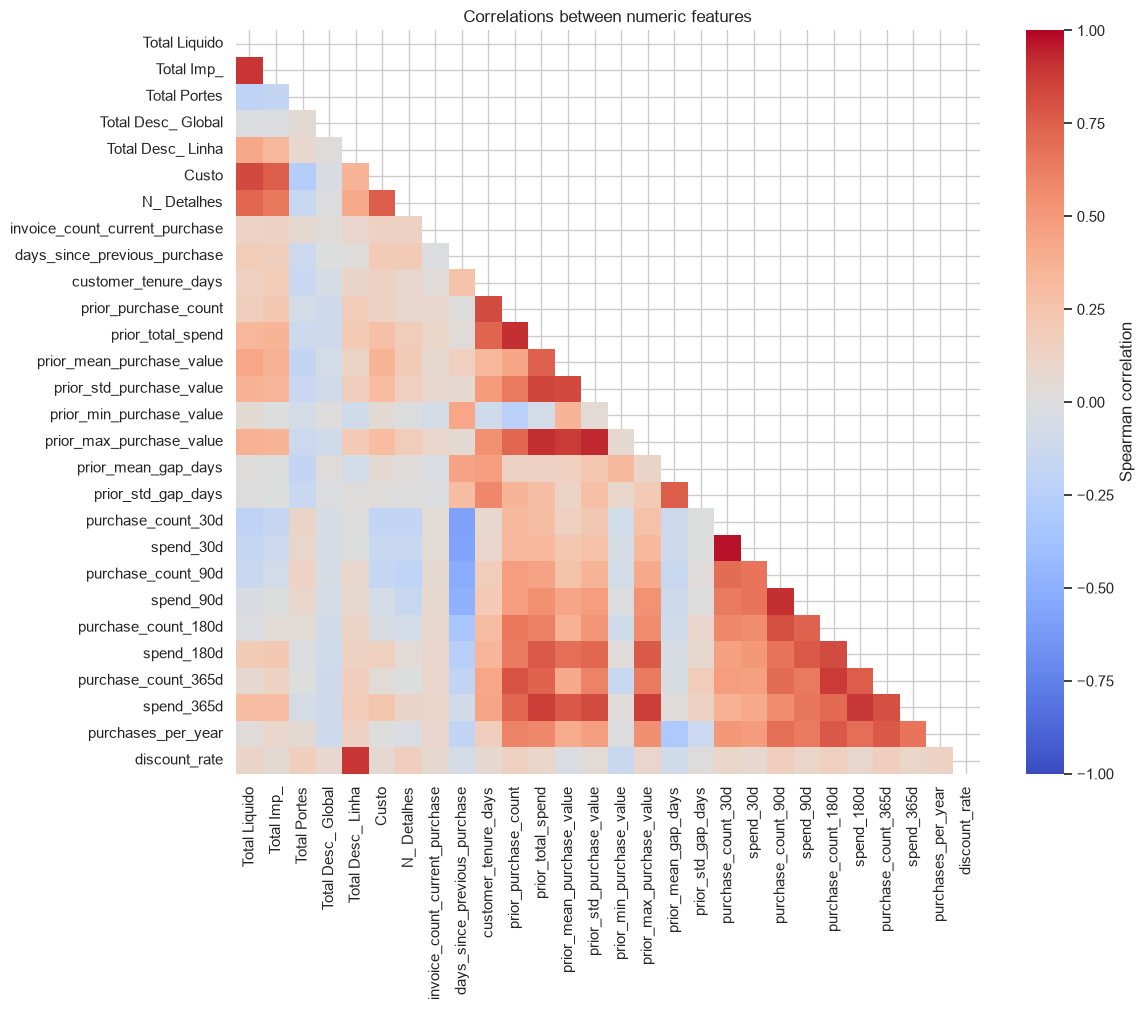

In [29]:
fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    correlation,
    mask=np.triu(np.ones(correlation.shape, dtype=bool)),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={"label": "Spearman correlation"},
    ax=ax,
)

ax.set_title("Correlations between numeric features")
plt.tight_layout()
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.2 Filter-based selection</h3>
<p>Retaining the top half of encoded features by mutual information in each training fold and compare their performance with the reference.</p>
</div>

In [30]:
def calculate_mi(matrix, target, names):
    discrete = np.array([
        name.startswith(("flags__", "cat__"))
        or name.split("__", 1)[-1] in count_features
        for name in names
    ])

    matrix_mi = matrix.copy()

    # Encode discrete values as integer category labels.
    for col_idx in np.flatnonzero(discrete):
        matrix_mi[:, col_idx] = np.unique(
            matrix[:, col_idx], return_inverse=True
        )[1]

    return mutual_info_classif(
        matrix_mi,
        target,
        discrete_features=discrete,
        random_state=RANDOMSTATE,
    )

In [31]:
# Evaluate MI-selected features using F1 at the fixed threshold.
mi_rows = []
mi_selected_features = {}

for fold, (trainidx, validx) in enumerate(splits, start=1):
    # Fit preprocessing only on this fold's training rows.
    fold_preprocessor = clone(pipeline)

    X_train = fold_preprocessor.fit_transform(X.iloc[trainidx])
    X_val = fold_preprocessor.transform(X.iloc[validx])

    names = (
        fold_preprocessor.named_steps["columns"]
        .get_feature_names_out()
    )

    # Rank features using training data only.
    scores = calculate_mi(X_train, y.iloc[trainidx], names)

    # Retain the top half of encoded features.
    n_keep = int(np.ceil(len(names) * 0.50))
    selected = np.argsort(-scores, kind="stable")[:n_keep]

    model = clone(reference_model.named_steps["model"])
    model.fit(X_train[:, selected], y.iloc[trainidx])

    positive_class = np.flatnonzero(model.classes_ == 1)[0]
    probabilities = model.predict_proba(
        X_val[:, selected]
    )[:, positive_class]

    fold_f1 = binary_f1(y.iloc[validx], probabilities)

    mi_selected_features[fold] = names[selected].tolist()

    mi_rows.append({
        "Fold": fold,
        "Available features": len(names),
        "Selected features": n_keep,
        "F1": fold_f1,
        "F1 change vs reference": (
            fold_f1 - reference_results.loc[fold, "F1"]
        ),
    })

    print(
        f"Fold {fold}: {n_keep} features, "
        f"F1 = {fold_f1:.4f}"
    )

mi_cv_results = pd.DataFrame(mi_rows).set_index("Fold")
display(mi_cv_results.round(4))

Fold 1: 45 features, F1 = 0.7503
Fold 2: 46 features, F1 = 0.7622
Fold 3: 46 features, F1 = 0.7222
Fold 4: 46 features, F1 = 0.7152
Fold 5: 44 features, F1 = 0.7495


,Available features,Selected features,F1,F1 change vs reference
Fold,,,,
1,90,45,0.7503,-0.0139
2,92,46,0.7622,0.0016
3,91,46,0.7222,-0.0070
4,92,46,0.7152,0.0016
5,88,44,0.7495,-0.0064


In [32]:
filter_comparison = pd.DataFrame({
    "Method": [
        "All candidate features",
        "Top 50% by MI",
    ],
    "Mean features": [
        reference_results["Encoded features"].mean(),
        mi_cv_results["Selected features"].mean(),
    ],
    "Mean F1": [
        reference_results["F1"].mean(),
        mi_cv_results["F1"].mean(),
    ],
    "F1 fold standard deviation": [
        reference_results["F1"].std(),
        mi_cv_results["F1"].std(),
    ],
}).set_index("Method")

display(filter_comparison.round(4))

print(
    "MI selection improved F1 over the reference in",
    int((mi_cv_results["F1 change vs reference"] > 0).sum()),
    f"of {len(splits)} folds.",
)

,Mean features,Mean F1,F1 fold standard deviation
Method,,,
All candidate features,90.6,0.7447,0.0222
Top 50% by MI,45.4,0.7399,0.0201


MI selection improved F1 over the reference in 2 of 5 folds.


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

Mutual information selection halves the feature count but reduces Mean F1 from 0.7447 to 0.7399, performing worse in three of five folds.

</div>

<a id="wrapper"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>5. Wrapper methods</h2>
Using recursive feature elimination (RFE) with logistic regression
</div>

In [33]:
rfe_rows = []
rfe_selected_features = {}

for fold, (trainidx, validx) in enumerate(splits, start=1):
    # Fit preprocessing on training rows only.
    fold_preprocessor = clone(pipeline)

    X_train = fold_preprocessor.fit_transform(X.iloc[trainidx])
    X_val = fold_preprocessor.transform(X.iloc[validx])

    names = (
        fold_preprocessor.named_steps["columns"]
        .get_feature_names_out()
    )

    n_keep = int(np.ceil(len(names) * 0.50))

    selector = RFE(
        estimator=clone(reference_model.named_steps["model"]),
        n_features_to_select=n_keep,
        step=5,
    )
    selector.fit(X_train, y.iloc[trainidx])

    positive_class = np.flatnonzero(selector.classes_ == 1)[0]
    probabilities = selector.predict_proba(X_val)[:, positive_class]
    fold_f1 = binary_f1(y.iloc[validx], probabilities)

    rfe_selected_features[fold] = names[selector.support_].tolist()

    rfe_rows.append({
        "Fold": fold,
        "Available features": len(names),
        "Selected features": int(selector.support_.sum()),
        "F1": fold_f1,
        "F1 change vs reference": (
            fold_f1 - reference_results.loc[fold, "F1"]
        ),
        "F1 change vs MI": (
            fold_f1 - mi_cv_results.loc[fold, "F1"]
        ),
    })

    print(
        f"Fold {fold}: {selector.support_.sum()} features, "
        f"F1 = {fold_f1:.4f}"
    )

rfe_cv_results = pd.DataFrame(rfe_rows).set_index("Fold")
display(rfe_cv_results.round(4))

Fold 1: 45 features, F1 = 0.7677
Fold 2: 46 features, F1 = 0.7681
Fold 3: 46 features, F1 = 0.7322
Fold 4: 46 features, F1 = 0.7175
Fold 5: 44 features, F1 = 0.7578


,Available features,Selected features,F1,F1 change vs reference,F1 change vs MI
Fold,,,,,
1,90,45,0.7677,0.0034,0.0173
2,92,46,0.7681,0.0074,0.0059
3,91,46,0.7322,0.0030,0.0100
4,92,46,0.7175,0.0039,0.0023
5,88,44,0.7578,0.0020,0.0084


In [34]:
selection_comparison = filter_comparison.copy()

selection_comparison.loc["Top 50% by RFE"] = {
    "Mean features": rfe_cv_results["Selected features"].mean(),
    "Mean F1": rfe_cv_results["F1"].mean(),
    "F1 fold standard deviation": rfe_cv_results["F1"].std(),
}

display(selection_comparison.round(4))

print(
    "RFE improved F1 over the reference in",
    int((rfe_cv_results["F1 change vs reference"] > 0).sum()),
    f"of {len(splits)} folds.",
)

print(
    "RFE improved F1 over MI in",
    int((rfe_cv_results["F1 change vs MI"] > 0).sum()),
    f"of {len(splits)} folds.",
)

,Mean features,Mean F1,F1 fold standard deviation
Method,,,
All candidate features,90.6,0.7447,0.0222
Top 50% by MI,45.4,0.7399,0.0201
Top 50% by RFE,45.4,0.7486,0.0227


RFE improved F1 over the reference in 5 of 5 folds.
RFE improved F1 over MI in 5 of 5 folds.


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

RFE halves the feature count with a Mean F1 of 0.7486, outperforming MI and the full-feature reference.
</div>


<a id="embedded"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>6. Embedded methods</h2>
</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<h2>6.1 L1-regularized logistic regression</h2>
<p> Selecting features with L1 coefficients. </p>
</div>

In [35]:
L1_C = 0.1

l1_rows = []
l1_selected_features = {}

for fold, (trainidx, validx) in enumerate(splits, start=1):
    fold_preprocessor = clone(pipeline)

    X_train = fold_preprocessor.fit_transform(X.iloc[trainidx])
    X_val = fold_preprocessor.transform(X.iloc[validx])

    names = (
        fold_preprocessor.named_steps["columns"]
        .get_feature_names_out()
    )

    # Select features using L1 on training data only.
    l1_selector = LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        C=L1_C,
        max_iter=5000,
        random_state=RANDOMSTATE,
    )
    l1_selector.fit(X_train, y.iloc[trainidx])

    selected = np.abs(l1_selector.coef_[0]) > 1e-8

    if not selected.any():
        raise ValueError(f"L1 selected no features in fold {fold}.")

    # Fit the reference classifier on the selected features.
    model = clone(reference_model.named_steps["model"])
    model.fit(X_train[:, selected], y.iloc[trainidx])

    positive_class = np.flatnonzero(model.classes_ == 1)[0]
    probabilities = model.predict_proba(
        X_val[:, selected]
    )[:, positive_class]

    fold_f1 = binary_f1(y.iloc[validx], probabilities)

    l1_selected_features[fold] = names[selected].tolist()

    l1_rows.append({
        "Fold": fold,
        "Available features": len(names),
        "Selected features": int(selected.sum()),
        "F1": fold_f1,
        "F1 change vs reference": (
            fold_f1 - reference_results.loc[fold, "F1"]
        ),
        "F1 change vs RFE": (
            fold_f1 - rfe_cv_results.loc[fold, "F1"]
        ),
    })

    print(
        f"Fold {fold}: {selected.sum()} features, "
        f"F1 = {fold_f1:.4f}"
    )

l1_cv_results = pd.DataFrame(l1_rows).set_index("Fold")
display(l1_cv_results.round(4))

Fold 1: 34 features, F1 = 0.7571
Fold 2: 38 features, F1 = 0.7601
Fold 3: 37 features, F1 = 0.7297
Fold 4: 39 features, F1 = 0.7165
Fold 5: 34 features, F1 = 0.7607


,Available features,Selected features,F1,F1 change vs reference,F1 change vs RFE
Fold,,,,,
1,90,34,0.7571,-0.0072,-0.0106
2,92,38,0.7601,-0.0006,-0.0080
3,91,37,0.7297,0.0005,-0.0024
4,92,39,0.7165,0.0029,-0.0010
5,88,34,0.7607,0.0049,0.0029


In [36]:
selection_comparison.loc["L1 selection (C=0.1)"] = {
    "Mean features": l1_cv_results["Selected features"].mean(),
    "Mean F1": l1_cv_results["F1"].mean(),
    "F1 fold standard deviation": l1_cv_results["F1"].std(),
}

display(selection_comparison.round(4))

print(
    "L1 selection improved F1 over the reference in",
    int((l1_cv_results["F1 change vs reference"] > 0).sum()),
    f"of {len(splits)} folds.",
)

print(
    "L1 selection improved F1 over RFE in",
    int((l1_cv_results["F1 change vs RFE"] > 0).sum()),
    f"of {len(splits)} folds.",
)

,Mean features,Mean F1,F1 fold standard deviation
Method,,,
All candidate features,90.6,0.7447,0.0222
Top 50% by MI,45.4,0.7399,0.0201
Top 50% by RFE,45.4,0.7486,0.0227
L1 selection (C=0.1),36.4,0.7448,0.0204


L1 selection improved F1 over the reference in 3 of 5 folds.
L1 selection improved F1 over RFE in 1 of 5 folds.


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<h2>6.2 L2-regularized logistic regression</h2>
<p> Evaluate stronger L2 regularization. </p>
</div>

In [37]:
ridge_rows = []

for fold, (trainidx, validx) in enumerate(splits, start=1):
    ridge_model = Pipeline([
        ("preprocessing", clone(pipeline)),
        ("model", LogisticRegression(
            l1_ratio=0,
            solver="lbfgs",
            C=0.1,
            max_iter=5000,
            random_state=RANDOMSTATE,
        )),
    ])

    ridge_model.fit(X.iloc[trainidx], y.iloc[trainidx])

    positive_class = np.flatnonzero(ridge_model.classes_ == 1)[0]
    probabilities = ridge_model.predict_proba(
        X.iloc[validx]
    )[:, positive_class]

    fold_f1 = binary_f1(y.iloc[validx], probabilities)

    names = (
        ridge_model.named_steps["preprocessing"]
        .named_steps["columns"]
        .get_feature_names_out()
    )

    ridge_rows.append({
        "Fold": fold,
        "Features": len(names),
        "F1": fold_f1,
        "F1 change vs reference": (
            fold_f1 - reference_results.loc[fold, "F1"]
        ),
    })

    print(
        f"Fold {fold}: {len(names)} features, "
        f"F1 = {fold_f1:.4f}"
    )

ridge_cv_results = pd.DataFrame(ridge_rows).set_index("Fold")
display(ridge_cv_results.round(4))

Fold 1: 90 features, F1 = 0.7660
Fold 2: 92 features, F1 = 0.7601
Fold 3: 91 features, F1 = 0.7287
Fold 4: 92 features, F1 = 0.7204
Fold 5: 88 features, F1 = 0.7614


,Features,F1,F1 change vs reference
Fold,,,
1,90,0.7660,0.0017
2,92,0.7601,-0.0006
3,91,0.7287,-0.0005
4,92,0.7204,0.0068
5,88,0.7614,0.0055


<a id="comparison"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<h2>7. Comparison and final feature set</h2>
</div>

In [38]:
model_comparison = selection_comparison.copy()

model_comparison.loc["Stronger L2 (C=0.1)"] = {
    "Mean features": ridge_cv_results["Features"].mean(),
    "Mean F1": ridge_cv_results["F1"].mean(),
    "F1 fold standard deviation": ridge_cv_results["F1"].std(),
}

model_comparison = model_comparison.sort_values(
    "Mean F1", ascending=False
)

display(model_comparison.round(4))
print(f"All methods evaluated at threshold {THRESHOLD:.2f}.")

,Mean features,Mean F1,F1 fold standard deviation
Method,,,
Top 50% by RFE,45.4,0.7486,0.0227
Stronger L2 (C=0.1),90.6,0.7473,0.0211
L1 selection (C=0.1),36.4,0.7448,0.0204
All candidate features,90.6,0.7447,0.0222
Top 50% by MI,45.4,0.7399,0.0201


All methods evaluated at threshold 0.50.


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<p>RFE achieves the highest Mean F1 Score, while L1 provides the smallest feature set</p>
</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<h3>7.1 Selection stability</h3>
<p>Counting how often each feature was selected across the five customer folds.</p>
</div>

In [39]:
# Use the original L1 results from Section 6.1.
selection_by_fold = pd.DataFrame({
    f"Fold {fold}": pd.Series(
        1, index=selected_names, dtype=int
    )
    for fold, selected_names in l1_selected_features.items()
}).fillna(0).astype(int)

selection_by_fold["Selected in folds"] = (
    selection_by_fold.sum(axis=1)
)

l1_stability = (
    selection_by_fold
    .sort_values("Selected in folds", ascending=False)
    .rename_axis("Feature")
)

display(l1_stability)

print(
    "Selected in all five folds:",
    (l1_stability["Selected in folds"] == 5).sum(),
)
print("Selected in at least one fold:", len(l1_stability))

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Selected in folds
Feature,,,,,,
cat__commercial_zone_Decorative Dashboard Zone 4,1,1,1,1,1,5
cat__month_Apr,1,1,1,1,1,5
cat__month_Aug,1,1,1,1,1,5
cat__month_Dec,1,1,1,1,1,5
cat__month_Jan,1,1,1,1,1,5
cat__month_Mar,1,1,1,1,1,5
cat__month_Nov,1,1,1,1,1,5
cat__month_Oct,1,1,1,1,1,5
cat__month_Sep,1,1,1,1,1,5


Selected in all five folds: 24
Selected in at least one fold: 49


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>L1 selects 24 features in all five folds, including purchase-history variables, eight month indicators and discount information, while other selections vary between folds.</p>
</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<h3>7.2 Final feature set</h3>
<p>Fitting the chosen L1 selection rule on all training rows and list the retained features.</p>
</div>

In [40]:
final_preprocessor = clone(pipeline)
X_all_prepared = final_preprocessor.fit_transform(X)

all_feature_names = (
    final_preprocessor.named_steps["columns"]
    .get_feature_names_out()
)

final_selector = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    C=L1_C,
    max_iter=5000,
    random_state=RANDOMSTATE,
)
final_selector.fit(X_all_prepared, y)

final_mask = np.abs(final_selector.coef_[0]) > 1e-8
final_features = all_feature_names[final_mask]

# Preserve the preprocessing column order.
final_feature_table = pd.DataFrame({
    "Feature": final_features,
    "Selected in CV folds": (
        l1_stability["Selected in folds"]
        .reindex(final_features, fill_value=0)
        .to_numpy()
    ),
})

display(final_feature_table)

print("Available encoded features:", len(all_feature_names))
print("Final selected features:", len(final_features))

,Feature,Selected in CV folds
0,log__Total Liquido,4
1,log__Total Imp_,5
2,log__Total Portes,3
3,log__Total Desc_ Linha,5
4,log__Custo,3
5,log__N_ Detalhes,2
6,log__invoice_count_current_purchase,4
7,log__customer_tenure_days,5
8,log__prior_purchase_count,5
9,log__prior_std_purchase_value,5


Available encoded features: 95
Final selected features: 41


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<p>The final L1 fit retains 41 encoded features covering purchase history, invoice characteristics customer categories and seasonality, including all 24 features selected in every validation fold. </p>
</div>

### Trying different prediction Models (already part of Task 4)

In [43]:
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)

# Fixed starting configurations; hyperparameter tuning comes later.
prediction_models = {
    "Logistic regression": clone(reference_model.named_steps["model"]),
    "Random forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOMSTATE,
    ),
    "Gradient boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=RANDOMSTATE,
    ),
}

model_feature_rows = []

for fold, (trainidx, validx) in enumerate(splits, start=1):
    # Fit preprocessing only on the training fold.
    fold_preprocessor = clone(pipeline)
    X_train = fold_preprocessor.fit_transform(X.iloc[trainidx])
    X_val = fold_preprocessor.transform(X.iloc[validx])

    y_train = y.iloc[trainidx]
    y_val = y.iloc[validx]

    names = (
        fold_preprocessor.named_steps["columns"]
        .get_feature_names_out()
    )
    n_features = len(names)
    n_keep = int(np.ceil(n_features * 0.50))

    # MI: select the top half using training data only.
    mi_scores = calculate_mi(X_train, y_train, names)
    mi_indices = np.argsort(-mi_scores, kind="stable")[:n_keep]

    # RFE: select half using the reference logistic regression.
    rfe_selector = RFE(
        estimator=clone(reference_model.named_steps["model"]),
        n_features_to_select=n_keep,
        step=5,
    )
    rfe_selector.fit(X_train, y_train)

    # L1: retain features with nonzero coefficients.
    l1_selector = LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        C=L1_C,
        max_iter=5000,
        random_state=RANDOMSTATE,
    )
    l1_selector.fit(X_train, y_train)
    l1_indices = np.flatnonzero(
        np.abs(l1_selector.coef_[0]) > 1e-8
    )

    if len(l1_indices) == 0:
        raise ValueError(f"L1 selected no features in fold {fold}.")

    feature_sets = {
        "All features": np.arange(n_features),
        "MI top 50%": mi_indices,
        "RFE top 50%": np.flatnonzero(rfe_selector.support_),
        "L1 selected": l1_indices,
    }

    # Use identical feature subsets for all classifiers in this fold.
    for feature_set, indices in feature_sets.items():
        for model_name, estimator in prediction_models.items():
            model = clone(estimator)
            model.fit(X_train[:, indices], y_train)

            positive_class = np.flatnonzero(model.classes_ == 1)[0]
            probabilities = model.predict_proba(
                X_val[:, indices]
            )[:, positive_class]

            fold_f1 = binary_f1(y_val, probabilities)

            model_feature_rows.append({
                "Fold": fold,
                "Model": model_name,
                "Feature set": feature_set,
                "Features": len(indices),
                "F1": fold_f1,
            })

    print(f"Fold {fold} complete: evaluated 12 combinations.")

# Keep individual fold results for later inspection.
model_feature_results = pd.DataFrame(model_feature_rows)

model_feature_comparison = (
    model_feature_results
    .groupby(["Model", "Feature set"], sort=False)
    .agg(
        mean_features=("Features", "mean"),
        mean_f1=("F1", "mean"),
        std_f1=("F1", "std"),
    )
    .rename(columns={
        "mean_features": "Mean features",
        "mean_f1": "Mean F1",
        "std_f1": "F1 fold standard deviation",
    })
    .sort_values("Mean F1", ascending=False)
)

display(model_feature_comparison.round(4))

# Compact view of how each classifier responds to feature selection.
f1_matrix = (
    model_feature_comparison["Mean F1"]
    .unstack("Feature set")
    .reindex(
        index=list(prediction_models),
        columns=["All features", "MI top 50%", "RFE top 50%", "L1 selected"],
    )
)

display(f1_matrix.round(4))
print(f"All combinations evaluated at threshold {THRESHOLD:.2f}.")

Fold 1 complete: evaluated 12 combinations.
Fold 2 complete: evaluated 12 combinations.
Fold 3 complete: evaluated 12 combinations.
Fold 4 complete: evaluated 12 combinations.
Fold 5 complete: evaluated 12 combinations.


Mean features  Mean F1  \
Model               Feature set                            
Logistic regression RFE top 50%            45.4   0.7486   
                    L1 selected            36.4   0.7448   
                    All features           90.6   0.7447   
Random forest       RFE top 50%            45.4   0.7437   
Logistic regression MI top 50%             45.4   0.7399   
Random forest       All features           90.6   0.7391   
                    L1 selected            36.4   0.7386   
Gradient boosting   RFE top 50%            45.4   0.7374   
                    All features           90.6   0.7373   
                    MI top 50%             45.4   0.7372   
Random forest       MI top 50%             45.4   0.7360   
Gradient boosting   L1 selected            36.4   0.7349   

                                  F1 fold standard deviation  
Model               Feature set                               
Logistic regression RFE top 50%                       0.0227  
                    L1 selected                       0.0204  
                    All features                      0.0222  
Random forest       RFE top 50%                       0.0193  
Logistic regression MI top 50%                        0.0201  
Random forest       All features                      0.0209  
                    L1 selected                       0.0210  
Gradient boosting   RFE top 50%                       0.0207  
                    All features                      0.0210  
                    MI top 50%                        0.0246  
Random forest       MI top 50%                        0.0255  
Gradient boosting   L1 selected                       0.0193

Feature set,All features,MI top 50%,RFE top 50%,L1 selected
Model,,,,
Logistic regression,0.7447,0.7399,0.7486,0.7448
Random forest,0.7391,0.7360,0.7437,0.7386
Gradient boosting,0.7373,0.7372,0.7374,0.7349


All combinations evaluated at threshold 0.50.


### Generating submissons for kaggle:

In [46]:
from sklearn.ensemble import RandomForestClassifier

# Fit four models on all training rows and export binary predictions.
test = pd.read_csv(DATA_DIR / "test.csv")

submission_dir = FINAL_DIR.parent / "submissions"
submission_dir.mkdir(parents=True, exist_ok=True)

assert test["ID"].notna().all()
assert test["ID"].is_unique

# Fit preprocessing on training data only.
submission_preprocessor = clone(pipeline)
X_train_submission = submission_preprocessor.fit_transform(X)
X_test_submission = submission_preprocessor.transform(test)

assert np.isfinite(X_train_submission).all()
assert np.isfinite(X_test_submission).all()

# L1 selection.
l1_submission_selector = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    C=L1_C,
    max_iter=5000,
    random_state=RANDOMSTATE,
)
l1_submission_selector.fit(X_train_submission, y)
l1_mask = np.abs(l1_submission_selector.coef_[0]) > 1e-8
assert l1_mask.any()

# RFE selection using logistic regression, matching local validation.
rfe_submission_selector = RFE(
    estimator=clone(reference_model.named_steps["model"]),
    n_features_to_select=int(
        np.ceil(X_train_submission.shape[1] * 0.50)
    ),
    step=5,
)
rfe_submission_selector.fit(X_train_submission, y)
rfe_mask = rfe_submission_selector.support_

submission_options = {
    "L1_Selected_LogReg": (
        l1_mask,
        clone(reference_model.named_steps["model"]),
    ),
    "All_Features_L2_C0p1": (
        np.ones(X_train_submission.shape[1], dtype=bool),
        LogisticRegression(
            l1_ratio=0,
            solver="lbfgs",
            C=0.1,
            max_iter=5000,
            random_state=RANDOMSTATE,
        ),
    ),
    "RFE50_Selected_LogReg": (
        rfe_mask,
        clone(reference_model.named_steps["model"]),
    ),
    "RFE50_RandomForest": (
        rfe_mask,
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=RANDOMSTATE,
        ),
    ),
}

submission_summary = []

for name, (mask, model) in submission_options.items():
    model.fit(X_train_submission[:, mask], y)

    positive_class = np.flatnonzero(model.classes_ == 1)[0]
    probabilities = model.predict_proba(
        X_test_submission[:, mask]
    )[:, positive_class]

    assert np.isfinite(probabilities).all()

    # Use the same threshold as in local F1 evaluation.
    predictions = (probabilities >= THRESHOLD).astype(int)

    # Preserve IDs and row order directly from test.csv.
    submission = pd.DataFrame({
        "ID": test["ID"].to_numpy(),
        TARGET: predictions,
    })

    assert len(submission) == len(test)
    assert submission[TARGET].isin([0, 1]).all()
    assert np.array_equal(
        submission["ID"].to_numpy(),
        test["ID"].to_numpy(),
    )

    output_path = submission_dir / f"ML_Group_30_Version_{name}.csv"
    submission.to_csv(output_path, index=False)

    submission_summary.append({
        "Model": name,
        "Features": int(mask.sum()),
        "Rows": len(submission),
        "Predicted 0": int((submission[TARGET] == 0).sum()),
        "Predicted 1": int((submission[TARGET] == 1).sum()),
        "File": output_path.name,
    })

display(pd.DataFrame(submission_summary))
print("Saved to:", submission_dir.resolve())

,Model,Features,Rows,Predicted 0,Predicted 1,File
0,L1_Selected_LogReg,41,986,352,634,ML_Group_30_Version_L1_Selected_LogReg.csv
1,All_Features_L2_C0p1,95,986,338,648,ML_Group_30_Version_All_Features_L2_C0p1.csv
2,RFE50_Selected_LogReg,48,986,335,651,ML_Group_30_Version_RFE50_Selected_LogReg.csv
3,RFE50_RandomForest,48,986,321,665,ML_Group_30_Version_RFE50_RandomForest.csv


Saved to: C:\Users\kroeh\OneDrive\Dokumente\Nova\MachineLearning\Project\Machine_Learning_Group30\submissions
